# GPS-Based Road Roughness Visualization

Road-condition predictions are mapped along the GPS route. Every trip is predicted by a model that was **trained without that vehicle-driver** (out-of-fold LOVO predictions from Notebook 07), so the maps show realistic performance for an unseen vehicle-driver, not memorised training data.

Two models are mapped: the full pipeline (C6) and the smartphone deployment model (C7).

In [1]:
# Setup: mount Drive and import the shared Component 4 pipeline (MyDrive/PVS_Code/c4_pipeline.py)
import os, sys, importlib
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

CODE_DIR = os.path.join(os.environ.get('C4_DRIVE', '/content/drive/MyDrive'), 'PVS_Code')
assert os.path.exists(os.path.join(CODE_DIR, 'c4_pipeline.py')), \
    'Upload c4_pipeline.py to MyDrive/PVS_Code/ before running this notebook.'
sys.path.insert(0, CODE_DIR)
import c4_pipeline as c4
importlib.reload(c4)
c4.ensure_dirs()
c4.check_setup();

Mounted at /content/drive
Drive folder      : /content/drive/MyDrive
Synced PVS1 found : True
Processed folder  : /content/drive/MyDrive/PVS_Processed True
Feature folder    : /content/drive/MyDrive/PVS_Feature_Datasets_v2 True
Results folder    : /content/drive/MyDrive/PVS_Model_Results_v2 True


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 180)
plt.rcParams['figure.dpi'] = 110
CL = c4.CLASSES
COLORS = {'good': 'tab:green', 'regular': 'goldenrod', 'bad': 'tab:red'}

In [3]:
data = c4.load_data()
PRED = pd.read_parquet(os.path.join(c4.RESULTS_DIR, 'lovo_out_of_fold_predictions.parquet'))
final = pd.read_csv(os.path.join(c4.RESULTS_DIR, 'final_results.csv'))
CHOICE = {}
for cfg in PRED.config.unique():
    CHOICE[cfg] = final[(final.config == cfg) & (final.split == 'LOVO')].groupby('model')['macro_f1'].mean().idxmax()
print('Mapped models:', CHOICE)

maps = []
for cfg, model in CHOICE.items():
    p = PRED[(PRED.config == cfg) & (PRED.model == model)].set_index('row')
    m = data.A.loc[p.index, ['pvs', 'vehicle', 'scenario', 'lat', 'lon', 'speed_mean']].copy()
    m['predicted'] = p['pred'].map(dict(enumerate(c4.CLASSES))).values
    m['actual'] = pd.Series(data.y[p.index]).map({-1: 'unlabelled', **dict(enumerate(c4.CLASSES))}).values
    m['evaluated'] = data.E[p.index]
    m['config'] = cfg
    maps.append(m)
MAPS = pd.concat(maps)
MAPS.to_csv(os.path.join(c4.RESULTS_DIR, 'gps_predictions.csv'), index=False)

Mapped models: {'C6 + Stable selection (FULL)': 'XGB', 'C7 Deployment (phone)': 'XGB'}


## 1. Agreement per trip

In [4]:
ev = MAPS[MAPS.evaluated]
agree = ev.assign(correct=ev.predicted == ev.actual).groupby(['config', 'pvs', 'vehicle'])['correct'].mean().mul(100).round(1)
display(agree.unstack('config'))

,config,C6 + Stable selection (FULL),C7 Deployment (phone)
pvs,vehicle,,
1,VW Saveiro,89.5,88.8
2,VW Saveiro,91.8,90.2
3,VW Saveiro,82.2,78.1
4,Fiat Bravo,91.5,90.9
5,Fiat Bravo,75.9,76.1
6,Fiat Bravo,92.9,93.4
7,Fiat Palio,89.0,87.0
8,Fiat Palio,91.3,90.0
9,Fiat Palio,79.1,79.6


## 2. Predicted vs. actual road condition along the route

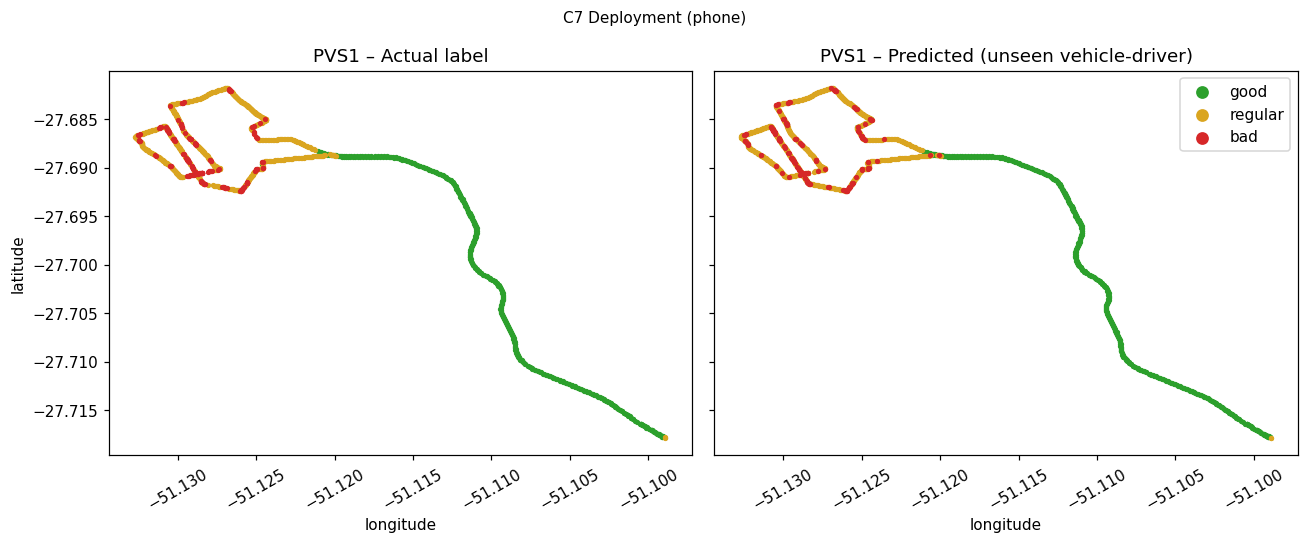

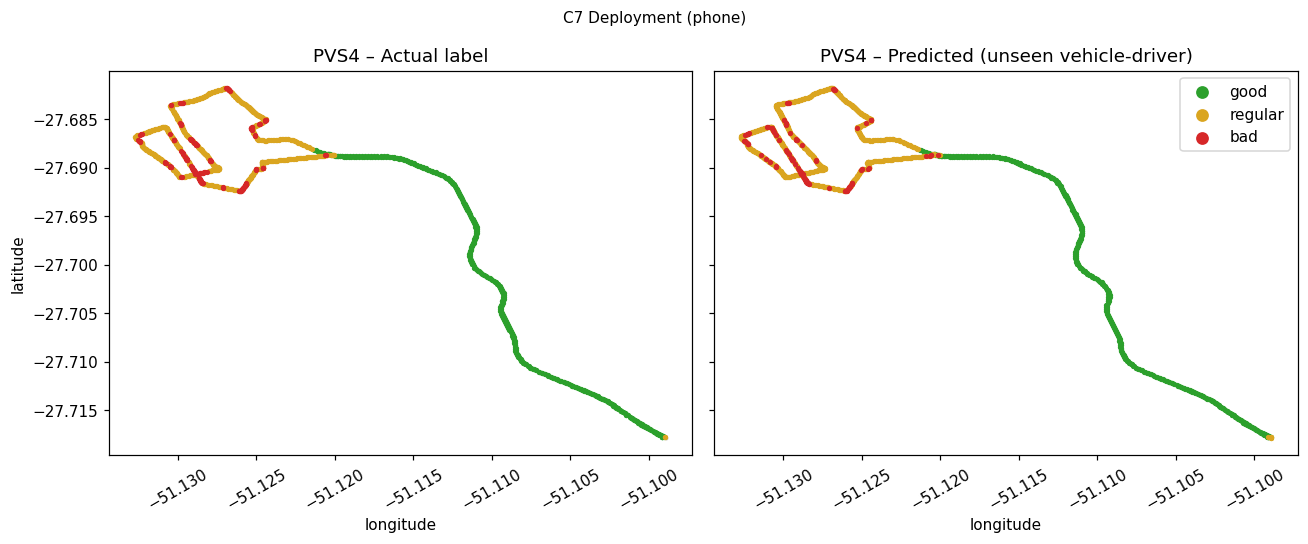

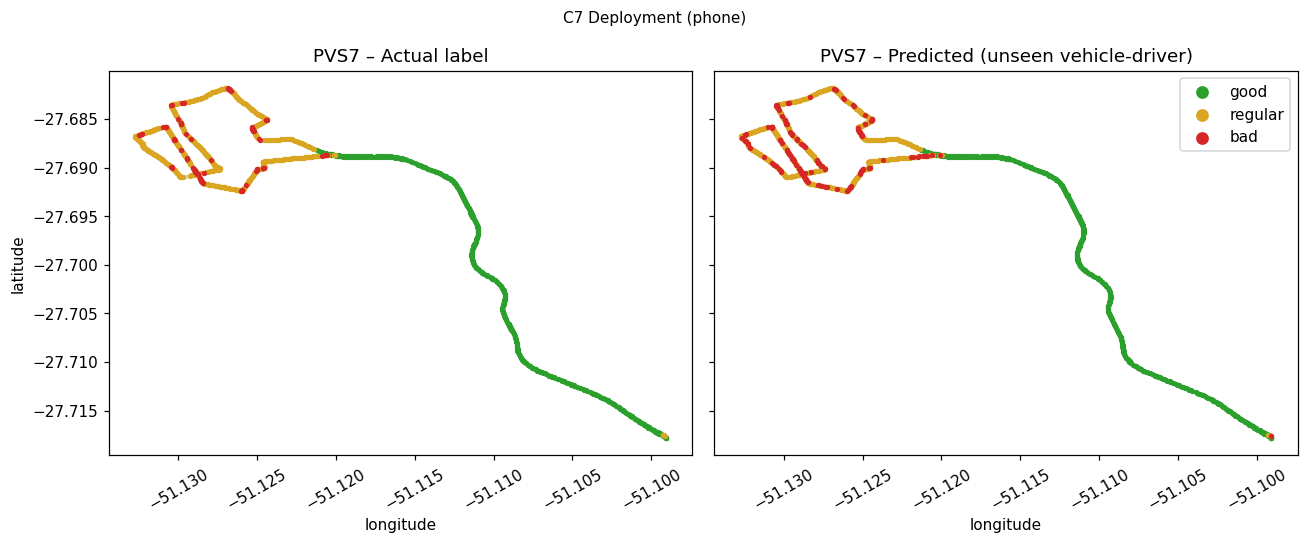

In [5]:
def route_plot(cfg, pvs):
    d = MAPS[(MAPS.config == cfg) & (MAPS.pvs == pvs)]
    fig, ax = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
    for a, col, title in [(ax[0], 'actual', 'Actual label'), (ax[1], 'predicted', 'Predicted (unseen vehicle-driver)')]:
        a.scatter(d.lon, d.lat, s=2, c='lightgrey')
        for cls in c4.CLASSES:
            s = d[d[col] == cls]
            a.scatter(s.lon, s.lat, s=6, c=COLORS[cls], label=cls)
        a.set_title(f'PVS{pvs} – {title}'); a.set_xlabel('longitude'); a.tick_params(axis='x', rotation=30)
    ax[0].set_ylabel('latitude'); ax[1].legend(markerscale=3)
    fig.suptitle(cfg, fontsize=10); plt.tight_layout()
    fig.savefig(os.path.join(c4.RESULTS_DIR, f'gps_PVS{pvs}_{cfg.split()[0]}.png'), dpi=150)
    plt.show()

for pvs in [1, 4, 7]:          # one trip per vehicle-driver
    route_plot('C7 Deployment (phone)', pvs)

## 3. Interactive map
The interactive map is saved as an HTML file. If the default tile server is blocked in Colab, the map still contains all points and can be opened from Google Drive in a browser.

In [6]:
try:
    import folium
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'folium'])
    import folium

d = MAPS[MAPS.config == 'C7 Deployment (phone)']
fmap = folium.Map(location=[d.lat.mean(), d.lon.mean()], zoom_start=13, tiles='CartoDB positron')
color = {'good': 'green', 'regular': 'orange', 'bad': 'red'}
for vehicle, g in d.groupby('vehicle'):
    layer = folium.FeatureGroup(name=vehicle)
    for _, r in g.iloc[::2].iterrows():
        folium.CircleMarker([r.lat, r.lon], radius=3, color=color[r.predicted], fill=True, fill_opacity=.8,
                            popup=f'PVS{r.pvs}: predicted {r.predicted}, actual {r.actual}, {r.speed_mean*3.6:.0f} km/h'
                            ).add_to(layer)
    layer.add_to(fmap)
folium.LayerControl().add_to(fmap)
html = os.path.join(c4.RESULTS_DIR, 'road_condition_map_deployment_model.html')
fmap.save(html)
print('Saved interactive map ->', html)

Saved interactive map -> /content/drive/MyDrive/PVS_Model_Results_v2/road_condition_map_deployment_model.html


## 4. Summary
* Each trip is coloured by the prediction of a model that never saw that vehicle-driver, which is the realistic situation for a new survey vehicle.
* The agreement table gives the per-trip accuracy on evaluated windows; unlabelled, speed-bump and manoeuvre windows are shown on the map but not scored.
* The same mapping is used later for smartphone data, where predictions come from the cloud service.